# 02: A pilot optimisation with the white-box physics

A deliberately simple baseline, to make the problem concrete and to give a yardstick for a better formulation:

- **A. Static allocation design (pilot problem P1).** For a given mass, M1 friction, voltage and airspeed, choose
  the thrust pair shares that minimise M1's wear rate, subject to headroom on every motor. Trade-off with pack current.
- **B. Ranking the counterfactual actions (P2).** At the decision time t_d of the counterfactual families, predict
  damage, SoC and headroom at landing for {none, payload, allocation, both} with a quasi-steady rollout (trim +
  wear law + battery), and compare with the four flights that were actually flown.
- **C. A wider action set and λ uncertainty.** Add diverts to the landing sites and mode-1 share allocations, and
  rank the options robustly over the uncertain wear rate λ.

Everything uses `hexakit.pilot` (trim = `whitebox.load_model.steady_state`). Limits of the model: steady phases only
(no turns, gusts, transients, controller dynamics), mean wind known, turbulence ignored.

In [1]:
import sys; sys.path.insert(0, "..")
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from hexakit import io, pilot
from hexakit.whitebox.allocation import AllocConfig
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
idx = io.flight_index()

## A. Static allocation design (P1)

Decision: pair shares s = (s₁₄, s₂₅, s₃₆) on the simplex (mode-1 allocation, S2 redistribution, uniform moment weights).

```
min_s   wear(s) = d₁ · (ω₁(s)/ω_ref)²             (∝ M1's wear rate db₁/dt)
s.t.    trim exists;  200 + m ≤ ω_cmd,k(s) ≤ 840 − m  for every motor k   (headroom margin m)
        (secondary objective: pack current I(s), i.e. energy)
```

ω₁(s) is the **actual** speed of M1 from the closed-loop trim, so the friction's own slowing effect is included.

In [2]:
MARGIN = 50.0     # rad/s headroom required on every motor, both limits
cases = [(1.0, 0.0), (3.0, 0.0), (6.0, 0.0), (3.0, 6.0)]     # (M1 friction factor, airspeed m/s)
grid = pilot.simplex_grid(n=30)
t0 = time.time(); scans = {}
for d1, vh in cases:
    s = pilot.static_allocation_scan(1.9, d1, v_batt=15.8, v_h=vh, shares=grid)
    s["feasible"] = s.ok & (s.headroom_hi >= MARGIN) & (s.headroom_lo >= MARGIN)
    scans[(d1, vh)] = s
print(f"{sum(len(s) for s in scans.values())} trims in {time.time() - t0:.0f} s")
uni = {k: pilot.trim(1.9, k[0], AllocConfig(), 15.8, k[1]) for k in cases}
rows = []
for k, s in scans.items():
    f = s[s.feasible]; b = f.loc[f.wear_rate_m1.idxmin()] if len(f) else None
    u = uni[k]
    rows.append(dict(d1=k[0], airspeed=k[1], feasible_share=f"{s.feasible.mean():.0%}",
                     uniform_wear=u["wear_rate_m1"], uniform_I=u["current"], uniform_headroom=min(u["headroom_hi"], u["headroom_lo"]),
                     best_s=None if b is None else (round(b.s14, 3), round(b.s25, 3), round(b.s36, 3)),
                     best_wear=None if b is None else b.wear_rate_m1, best_I=None if b is None else b.current_A,
                     wear_reduction=None if b is None else 1 - b.wear_rate_m1 / u["wear_rate_m1"]))
pd.DataFrame(rows).round(3)

1300 trims in 10 s


,d1,airspeed,feasible_share,uniform_wear,uniform_I,uniform_headroom,best_s,best_wear,best_I,wear_reduction
0,1.0,0.0,72%,0.999,14.310,313.417,"(0.1, 0.433, 0.467)",0.313,14.519,0.686
1,3.0,0.0,50%,2.183,17.898,179.819,"(0.133, 0.433, 0.433)",0.825,15.945,0.622
2,6.0,0.0,21%,2.715,22.044,68.395,"(0.2, 0.4, 0.4)",1.475,18.802,0.457
3,3.0,6.0,50%,2.177,17.678,182.515,"(0.133, 0.433, 0.433)",0.820,15.774,0.624


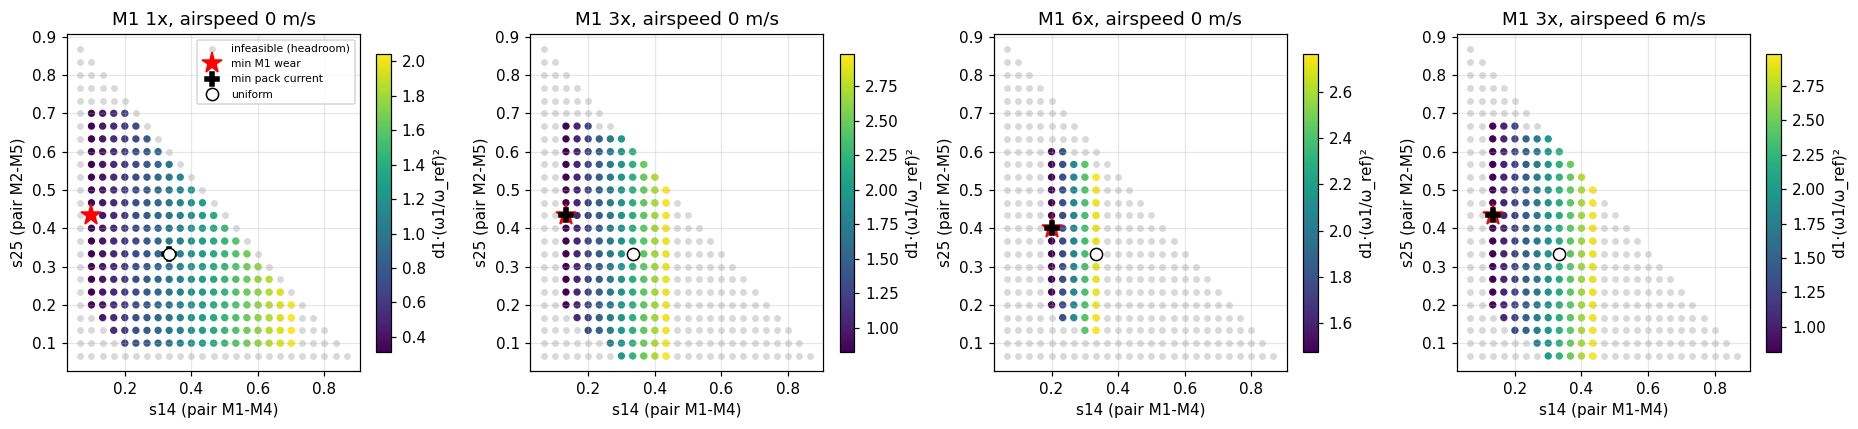

In [3]:
fig, axs = plt.subplots(1, len(cases), figsize=(17, 4))
for ax, (k, s) in zip(axs, scans.items()):
    f = s[s.feasible]
    ax.scatter(s.s14, s.s25, c="0.85", s=12, label="infeasible (headroom)")
    sc = ax.scatter(f.s14, f.s25, c=f.wear_rate_m1, s=14, cmap="viridis")
    b = f.loc[f.wear_rate_m1.idxmin()]; e = f.loc[f.current_A.idxmin()]
    ax.plot(b.s14, b.s25, "r*", ms=14, label="min M1 wear"); ax.plot(e.s14, e.s25, "kP", ms=9, label="min pack current")
    ax.plot(1/3, 1/3, "wo", mec="k", ms=8, label="uniform")
    ax.set(title=f"M1 {k[0]:.0f}x, airspeed {k[1]:.0f} m/s", xlabel="s14 (pair M1-M4)", ylabel="s25 (pair M2-M5)")
    plt.colorbar(sc, ax=ax, fraction=0.046, label="d1·(ω1/ω_ref)²")
axs[0].legend(fontsize=7, loc="upper right"); plt.tight_layout(); plt.show()

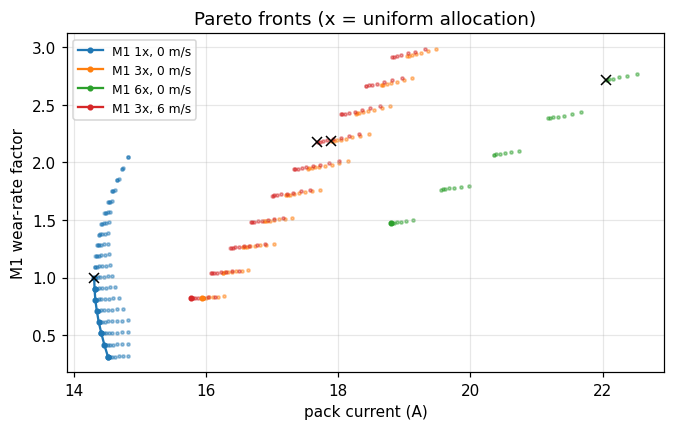

In [4]:
# Pareto front: M1 wear rate vs pack current (feasible designs), per case
fig, ax = plt.subplots(figsize=(7, 4))
for k, s in scans.items():
    f = s[s.feasible].sort_values("current_A")
    pf = f[f.wear_rate_m1 <= f.wear_rate_m1.cummin()]
    ax.scatter(f.current_A, f.wear_rate_m1, s=4, alpha=0.25)
    ax.plot(pf.current_A, pf.wear_rate_m1, "-o", ms=3, label=f"M1 {k[0]:.0f}x, {k[1]:.0f} m/s")
    ax.plot(uni[k]["current"], uni[k]["wear_rate_m1"], "kx")
ax.set(xlabel="pack current (A)", ylabel="M1 wear-rate factor", title="Pareto fronts (x = uniform allocation)"); ax.legend(fontsize=8)
plt.show()

**What this shows.**
- Unloading the M1–M4 pair (small s₁₄) cuts M1's wear rate several-fold at a modest current cost. The limit is the
  **other** constraint: M4 shares M1's speed (pair coupling), and it hits the 200 rad/s floor. Raising the floor
  margin or the friction shrinks the feasible set.
- Where the remaining thrust goes (s₂₅ vs s₃₆) hardly matters for M1, but it matters for the headroom of M2/M5 vs
  M3/M6. With a fault on a second motor it would matter a lot.
- Exercise: add the M1 ceiling `om1_max` and the saturation strategy as decision variables; add a margin on the
  **moment** authority (not only commands) via an LP over the mixer matrix.

## B. Ranking the counterfactual actions at t_d (P2)

For each counterfactual family: use only what is known at t_d (the shared history, the plan, the mean wind), then
predict the remainder of the mission for each action with `pilot.evaluate_actions`:
- the trim at each 2 s step of the remaining plan gives M1's actual speed and the pack current;
- the friction grows by the wear law (exact step), so the health → load → wear feedback is included;
- the battery is integrated with its 1-RC model, and the voltage feeds the next trim.

Two simplifications are **oracles** to be replaced: the current friction d(t_d) is the true one (in practice: the
encoder z mapped to d), and λ is the design value (in practice: estimated from the history; see the check below).

In [5]:
cf = idx[idx.subset == "counterfactual_cf"]
res, rows = {}, []
for fam, g in cf.groupby("family_id"):
    fn = io.load_flight(g[g.cf_branch == "none"].flight_id.iloc[0]); td = fn["meta"]["cf_t_dec_s"]
    print(f"{fam}: t_d = {td:.0f} s, d(t_d) = {fn['d'][np.searchsorted(fn['t'], td)]:.2f}x, "
          f"λ design {pilot.lambda_oracle(fn['meta']):.2e}, λ from the last 60 s of history {pilot.lambda_from_history(fn, td):.2e} 1/s")
    res[fam] = (fn, td, pilot.evaluate_actions(fn, td))
    for b, (s, r) in res[fam][2].items():
        tru = g[g.cf_branch == b].iloc[0]
        rows.append(dict(family=fam, action=b, pred_d_end=s["d1_end"], true_d_end=tru.friction_end_x,
                         pred_soc_end=100 * s["soc_end"], true_soc_end=tru["Final SOC (%)"],
                         pred_min_headroom=s["min_headroom_hi"], true_M1_at_840_s=tru["diag: M1 at 840 (s)"],
                         true_outcome=tru.outcome, true_failed=tru["Failed checks"]))
cmp_ = pd.DataFrame(rows); cmp_.round(2)

S487: t_d = 179 s, d(t_d) = 1.82x, λ design 7.18e-03, λ from the last 60 s of history 7.18e-03 1/s


S496: t_d = 167 s, d(t_d) = 1.89x, λ design 6.83e-03, λ from the last 60 s of history 6.83e-03 1/s


S501: t_d = 225 s, d(t_d) = 1.82x, λ design 5.70e-03, λ from the last 60 s of history 5.70e-03 1/s


,family,action,pred_d_end,true_d_end,pred_soc_end,true_soc_end,pred_min_headroom,true_M1_at_840_s,true_outcome,true_failed
0,S487,none,4.40,4.42,75.15,75.01,91.89,0.00,FAIL,Landing (F7)
1,S487,payload,4.15,4.16,76.40,76.32,141.67,0.00,FAIL,Landing (F7)
2,S487,alloc,2.78,2.79,77.05,76.93,208.55,0.00,FAIL,Landing (F7)
3,S487,alloc_payload,2.70,2.70,78.03,77.97,238.32,0.00,FAIL,Landing (F7)
4,S496,none,4.68,4.76,71.33,70.75,0.00,12.17,MISSION PASS,NaN
5,S496,payload,4.47,4.56,72.45,71.91,25.44,0.67,MISSION PASS,NaN
6,S496,alloc,2.92,2.96,73.67,73.23,120.10,0.00,MISSION PASS,NaN
7,S496,alloc_payload,2.85,2.88,74.54,74.14,145.48,0.00,MISSION PASS,NaN
8,S501,none,4.31,4.40,69.08,68.45,74.93,0.00,FAIL,Ground impact (F6b); Landing (F7); Corridor (F...
9,S501,payload,4.07,4.15,70.66,70.10,125.52,0.00,FAIL,Ground impact (F6b); Landing (F7); Corridor (F8)


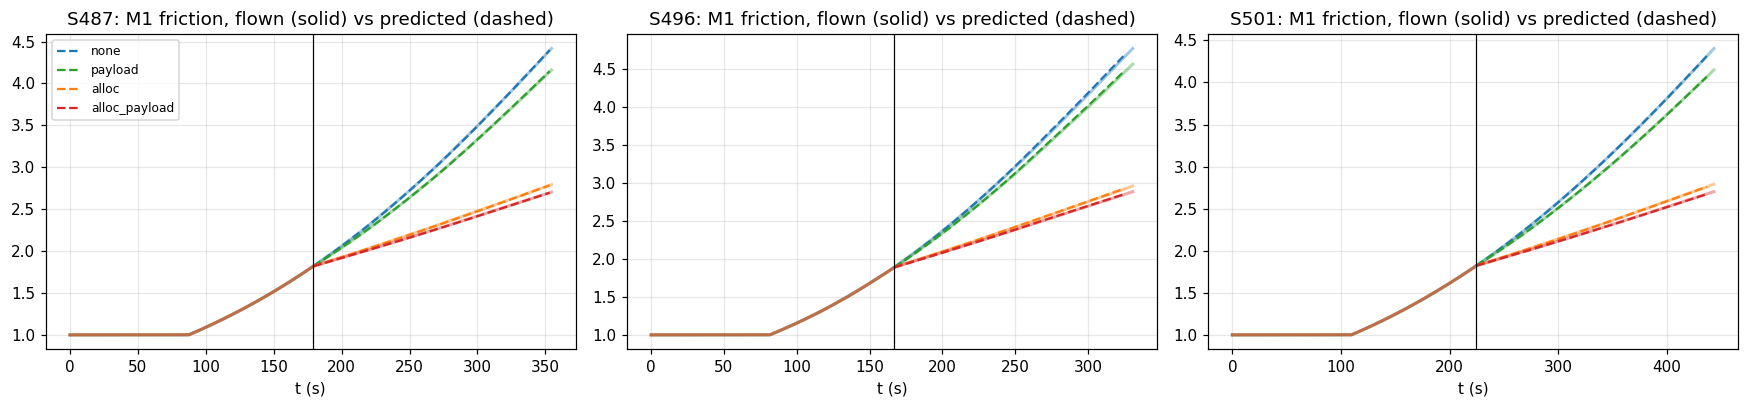

Ranking by predicted damage matches the flown damage ranking in every family: True


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (fam, (fn, td, out)) in zip(axs, res.items()):
    for (b, (s, r)), c in zip(out.items(), ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
        fid = cf[(cf.family_id == fam) & (cf.cf_branch == b)].flight_id.iloc[0]
        f = io.load_flight(fid)
        ax.plot(f["t"], f["d"], c=c, lw=2, alpha=0.4); ax.plot(r.t, r.d1, "--", c=c, label=f"{b}")
    ax.axvline(td, c="k", lw=0.8); ax.set(title=f"{fam}: M1 friction, flown (solid) vs predicted (dashed)", xlabel="t (s)")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print("Ranking by predicted damage matches the flown damage ranking in every family:",
      all((g.sort_values("pred_d_end").action.tolist() == g.sort_values("true_d_end").action.tolist()) for _, g in cmp_.groupby("family")))

**What this shows.**
- Damage and SoC at landing are predicted within a few percent, and the damage **ranking** is right. The white-box
  chain (trim + wear law + battery) is a usable forecaster when λ and the current friction are known.
- But the outcome is **not** predicted. S501 `none` fails although the trim never runs out of headroom: the
  vehicle lands 1.26 m from B (limit 1 m), because with no integral action a worn M1 leaves a steady position offset.
  S487 fails the landing check in every branch, including healthy ones. The constraints that decide the outcome
  (landing accuracy, corridor, divergence in gusts or turns) are dynamic, and a steady-state model can't see them.
  This is why the project needs a closed-loop rollout, or a learned outcome model (P3), as the constraint model.

## C. A wider action set, and robustness to λ

At t_d of family S501 we enumerate a mixed action set:
- allocation ∈ {uniform, legacy (4, 1, 1, 1, 1, 1), mode-1 pair shares with s₁₄ ∈ {0.25, 0.15}};
- payload ∈ {keep, drop 0.15 kg};
- destination ∈ {B (continue), A, L1, L2, L3, L4}.

Mode-1 allocations cannot be switched in flight in the simulator today (hypothetical actions). Diverts use a
straight-line plan with a 1.3 detour factor (the real planner goes around buildings). λ is uncertain: we evaluate
λ ∈ {0.5, 1, 1.5} × the design value and keep the worst case.

In [7]:
fam = "S501"; fn, td, _ = res[fam]
st = pilot.state_at(fn, td); meta = fn["meta"]
lam0 = pilot.lambda_oracle(meta); wind = pilot.wind_vector(meta["wind_speed_ms"], meta["wind_from_deg"])
v_now = float(fn["speed_cmd_ms"][np.searchsorted(fn["t"], td)]); alt = float(meta["altitude_m"])
sites = io.load_map()["sites"]["landing_sites"]
allocs = {"uniform": AllocConfig(), "legacy 4:1": AllocConfig.legacy([4, 1, 1, 1, 1, 1]),
          "shares s14=.25": AllocConfig(mode=1, shares=np.array([.25, .375, .375]), sat=2),
          "shares s14=.15": AllocConfig(mode=1, shares=np.array([.15, .425, .425]), sat=2)}
plans = {"B": pilot.remaining_plan(fn, td, dt=4.0)}
for k, xy in sites.items():
    plans[k] = pilot.divert_plan(st, xy, v_now, alt, wind, dt=4.0, detour=1.3)
rows = []; t0 = time.time()
for dest, plan in plans.items():
    for an, a in allocs.items():
        for drop in (0.0, 0.15):
            for lf in (0.5, 1.0, 1.5):
                r = pilot.rollout(plan, st["mass_kg"] - drop, st["d1"], lf * lam0, a, st["soc"], st["i_pack"])
                s = pilot.summarize(r)
                rows.append(dict(dest=dest, alloc=an, drop_kg=drop, lam_factor=lf, duration_s=float(plan.t.iloc[-1] - plan.t.iloc[0]), **s))
opt = pd.DataFrame(rows); print(f"{len(opt)} rollouts in {time.time() - t0:.0f} s")
# robust summary over λ: worst case
rob = opt.groupby(["dest", "alloc", "drop_kg"]).agg(d1_end_worst=("d1_end", "max"), soc_end_worst=("soc_end", "min"),
                                                    headroom_worst=("min_headroom_hi", "min"), floor_worst=("min_headroom_lo", "min"),
                                                    duration_s=("duration_s", "first")).reset_index()
rob["feasible"] = (rob.soc_end_worst >= 0.30) & (rob.headroom_worst >= 50) & (rob.floor_worst >= 0)
rob.sort_values(["feasible", "d1_end_worst"], ascending=[False, True]).round(3).head(15)

144 rollouts in 109 s


,dest,alloc,drop_kg,d1_end_worst,soc_end_worst,headroom_worst,floor_worst,duration_s,feasible
33,L3,legacy 4:1,0.15,2.316,0.808,248.640,95.063,84.0,True
35,L3,shares s14=.15,0.15,2.316,0.808,249.086,98.288,84.0,True
32,L3,legacy 4:1,0.00,2.365,0.803,218.087,108.425,84.0,True
34,L3,shares s14=.15,0.00,2.367,0.803,218.671,112.349,84.0,True
17,L1,legacy 4:1,0.15,2.567,0.782,244.950,86.853,124.0,True
19,L1,shares s14=.15,0.15,2.576,0.782,246.405,92.483,124.0,True
16,L1,legacy 4:1,0.00,2.642,0.775,212.331,99.123,124.0,True
18,L1,shares s14=.15,0.00,2.654,0.775,214.008,105.712,124.0,True
41,L4,legacy 4:1,0.15,2.669,0.772,242.393,83.636,140.0,True
43,L4,shares s14=.15,0.15,2.682,0.772,244.024,90.110,140.0,True


Lexicographic choice:
 {'dest': 'B', 'alloc': 'legacy 4:1', 'drop_kg': 0.0, 'd1_end_worst': 3.2713074092746215, 'soc_end_worst': 0.7122326176816087, 'headroom_worst': 189.9748192433567}
Weighted choice (damage + mission value lost):
 {'dest': 'B', 'alloc': 'legacy 4:1', 'drop_kg': 0.0, 'd1_end_worst': 3.2713074092746215}


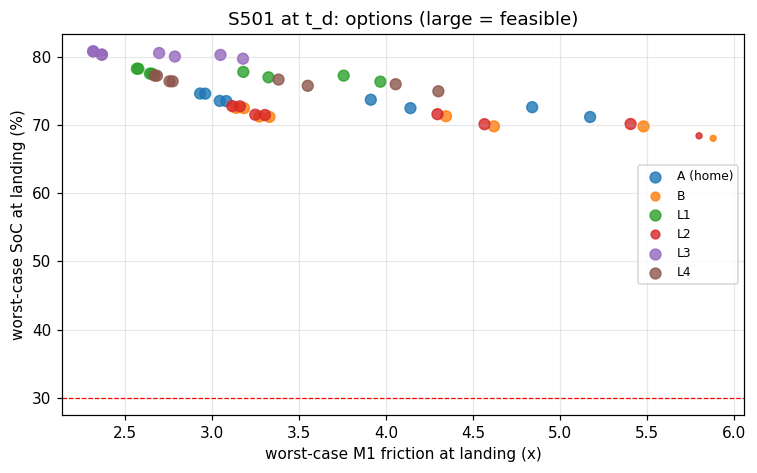

In [8]:
# A lexicographic decision in the spirit of the project's placeholder policy: deliver to B if feasible; prefer keeping
# the payload; then minimise worst-case damage. Then a weighted alternative.
feas = rob[rob.feasible]
order = feas.assign(not_B=feas.dest != "B", dropped=feas.drop_kg > 0).sort_values(["not_B", "dropped", "d1_end_worst"])
print("Lexicographic choice:\n", order.iloc[0][["dest", "alloc", "drop_kg", "d1_end_worst", "soc_end_worst", "headroom_worst"]].to_dict())
w_damage, w_value = 1.0, {"B": 0.0, "A (home)": 2.0}
score = feas.d1_end_worst * w_damage + feas.dest.map(lambda d: w_value.get(d, 3.0)) + 1.0 * (feas.drop_kg > 0)
print("Weighted choice (damage + mission value lost):\n", feas.loc[score.idxmin()][["dest", "alloc", "drop_kg", "d1_end_worst"]].to_dict())
fig, ax = plt.subplots(figsize=(8, 4.5))
for dest, g in rob.groupby("dest"):
    ax.scatter(g.d1_end_worst, 100 * g.soc_end_worst, s=np.where(g.feasible, 50, 15), label=dest, alpha=0.8)
ax.axhline(30, c="r", ls="--", lw=0.8); ax.set(xlabel="worst-case M1 friction at landing (x)", ylabel="worst-case SoC at landing (%)",
                                               title=f"{fam} at t_d: options (large = feasible)"); ax.legend(fontsize=8); plt.show()

## Take-aways for a formalisation

1. **The physics gives cheap and accurate damage/energy predictions** (given friction and λ). The hard parts are
   (i) the uncertainty of λ and of the health estimate early after the onset, and (ii) the outcome constraints,
   which are dynamic (landing accuracy, corridor, divergence) and cliff-like.
2. **The action space is mixed and structured.** The shares live on a simplex with a closed-form feasible region.
   Diverts and the payload are discrete. Opposite motors are coupled.
3. **Feasible ≠ safe.** A steady-state headroom margin is a proxy. An outcome surrogate learned from the manifests
   (2,523 graded flights) or closed-loop rollouts are needed to turn it into a chance constraint.
4. Ideas: scenario-based robust ranking over λ̂ samples; receding-horizon re-decision as λ̂ tightens; an offline
   policy table over (z, λ̂, distance left, mass, wind).